# 04 · Model selection, hyperparameter tuning and final test evaluation

All on the **discovered-k** label set from notebook 02.

Notebook 03 showed one full-size BERT run takes ~80 min on Kaggle's T4s, so every training here uses
a class-balanced **20k-paper subset** of the training split (validation and test stay full-size).

1. **Model selection:** `bert-base-uncased` vs `bert-base-cased` vs `distilbert-base-uncased`,
   all with the default configuration.
   All three are Apache-2.0 English BERT-family checkpoints with TensorFlow weights, as the task's
   Hugging Face filter asks.
2. **Optuna** (TPE sampler, median pruner) on the winner: learning rate, batch size, epochs, warmup,
   weight decay, max length, loss (weighted CE vs focal) and dropout. Trials use a 10k-paper subset
   of that; the first trial is the default configuration.
3. **Baseline grid search:** C × n-gram range × class weighting for TF-IDF + logistic regression.
4. **Final:** retrain default and tuned configurations on the 20k subset with up to 3 seeds each,
   then evaluate once on the held-out **test** split (mean ± std).

Runs on a Kaggle GPU (T4 ×2) under a hard 6 h time budget (see `BUDGET_HOURS`).

In [1]:
import glob
import shutil
import sys
from pathlib import Path


def add_src_to_path():
    hits = glob.glob("/kaggle/input/**/taxonomy.py", recursive=True)
    if hits:
        pkg = Path("/tmp/pkg/src")
        shutil.copytree(Path(hits[0]).parent, pkg, dirs_exist_ok=True)
        sys.path.insert(0, str(pkg.parent))
    else:
        sys.path.insert(0, str(Path.cwd().parent))


add_src_to_path()

from dataclasses import asdict, replace

import time

import matplotlib.pyplot as plt
import optuna
import pandas as pd
import torch

from src import evaluate, taxonomy, viz
from src.train import LabelSpace, TrainConfig, tfidf_logreg, train_transformer
from src.tune import baseline_grid, mean_std, optuna_search
from src.utils import FIG_DIR, RESULTS_DIR, ensure_dirs, find_input, load_json, save_json, set_seed

set_seed()
ensure_dirs()
viz.apply_style()
optuna.logging.set_verbosity(optuna.logging.WARNING)
assert torch.cuda.is_available(), "No GPU: set Accelerator to GPU (needs a phone-verified Kaggle account)"

N_TRIALS = 12
# Kaggle kills a session at 12 h. The notebook keeps its own clock and stops starting new work
# once the next step would not fit in BUDGET_HOURS, so a slow GPU costs runs, never the whole session.
BUDGET_HOURS = 6.0
T0 = time.time()


def hours_left():
    return BUDGET_HOURS - (time.time() - T0) / 3600


TRAIN_SUBSET = 20_000
TUNE_SUBSET = 10_000
SEEDS = [42, 43, 44]

train = pd.read_parquet(find_input("train.parquet"))
val = pd.read_parquet(find_input("val.parquet"))
test = pd.read_parquet(find_input("test.parquet"))
best_k = load_json(find_input("best_k.json"))
discovered = taxonomy.discovered_label(best_k["mapping"])
for df in (train, val, test):
    df["label"] = df["fine"].map(discovered)
train = (train.groupby("label", group_keys=False).sample(frac=TRAIN_SUBSET / len(train), random_state=0)
         .reset_index(drop=True))
sp = LabelSpace(train["label"])
y_tr, y_va, y_te = (sp.encode(d["label"]) for d in (train, val, test))
print("classes:", len(sp), "| train/val/test:", len(train), len(val), len(test))

classes: 12 | train/val/test: 20000 7400 7400


## 1. Model selection

In [2]:
selection = []
for name in ["bert-base-uncased", "bert-base-cased", "distilbert-base-uncased"]:
    scores, info = train_transformer(TrainConfig(model_name=name), train["text"], y_tr,
                                     {"val": (val["text"], y_va)}, len(sp), f"/tmp/ckpt/sel_{name}")
    m = evaluate.metrics(y_va, scores["val"], sp.names)
    selection.append({"model_name": name, "macro_f1": m["macro_f1"], "accuracy": m["accuracy"],
                      "train_seconds": info["train_seconds"]})
    print(selection[-1])
    torch.cuda.empty_cache()
selection = pd.DataFrame(selection).sort_values("macro_f1", ascending=False)
selection.to_csv(RESULTS_DIR / "model_selection.csv", index=False)
BEST_MODEL = selection.iloc[0]["model_name"]
print("selected:", BEST_MODEL)
selection

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

...

{'eval_loss': '0.7003', 'eval_macro_f1': '0.7719', 'eval_accuracy': '0.7638', 'eval_runtime': '30.91', 'eval_samples_per_second': '239.4', 'eval_steps_per_second': '1.877', 'epoch': '3'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'train_runtime': '883.4', 'train_samples_per_second': '67.92', 'train_steps_per_second': '2.122', 'train_loss': '0.8229', 'epoch': '3'}


{'model_name': 'distilbert-base-uncased', 'macro_f1': 0.7718655628243042, 'accuracy': 0.7637837837837838, 'train_seconds': 883.8861122131348}
selected: bert-base-uncased


,model_name,macro_f1,accuracy,train_seconds
0,bert-base-uncased,0.778927,0.771351,1747.496840
1,bert-base-cased,0.777077,0.770676,1752.575626
2,distilbert-base-uncased,0.771866,0.763784,883.886112


## 2. Optuna search

In [3]:
sub = train.groupby("label", group_keys=False).sample(frac=TUNE_SUBSET / len(train), random_state=0)
# Reserve time for two full final runs (one default, one tuned) plus the baseline grid, using the
# measured duration of a full BERT run from notebook 03 and of the model-selection runs above.
RUN_HOURS = selection["train_seconds"].max() / 3600 * 1.15
optuna_hours = hours_left() - 2 * RUN_HOURS - 0.75
print(f"full run ~ {RUN_HOURS:.2f} h | Optuna budget {optuna_hours:.2f} h")
study = optuna_search(TrainConfig(model_name=BEST_MODEL), sub["text"], sp.encode(sub["label"]),
                      val["text"], y_va, len(sp), N_TRIALS, timeout=max(optuna_hours, 0.25) * 3600)
trials = study.trials_dataframe()
trials.to_csv(RESULTS_DIR / "optuna_trials.csv", index=False)
print("best trial:", study.best_trial.number, study.best_value, study.best_params)
trials[["number", "value", "state"] + [c for c in trials.columns if c.startswith("params_")]].round(5)

full run ~ 0.56 h | Optuna budget 2.86 h


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Map:   0%|          | 0/10001 [00:00<?, ? examples/s]

Map:   0%|          | 0/7400 [00:00<?, ? examples/s]

...

{'loss': '2.019', 'grad_norm': '4.341', 'learning_rate': '5.297e-05', 'epoch': '0.3195'}


{'loss': '1.02', 'grad_norm': '8.581', 'learning_rate': '8.434e-05', 'epoch': '0.639'}


{'loss': '0.9341', 'grad_norm': '10.73', 'learning_rate': '7.633e-05', 'epoch': '0.9585'}


{'eval_loss': '0.9293', 'eval_macro_f1': '0.6976', 'eval_accuracy': '0.6888', 'eval_runtime': '62.03', 'eval_samples_per_second': '119.3', 'eval_steps_per_second': '0.935', 'epoch': '1'}
best trial: 8 0.7661513852527682 {'learning_rate': 9.682112333570124e-05, 'batch_size': 32, 'epochs': 3, 'warmup_ratio': 0.07712288059246292, 'weight_decay': 0.05269810603715661, 'max_length': 256, 'loss': 'weighted_ce', 'dropout': 0.07015242400752526}


,number,value,state,params_batch_size,params_dropout,params_epochs,params_learning_rate,params_loss,params_max_length,params_warmup_ratio,params_weight_decay
0,0,0.75192,COMPLETE,32,0.10000,3,0.00002,weighted_ce,256,0.10000,0.01000
1,1,0.72097,COMPLETE,16,0.24973,2,0.00002,focal,128,0.02340,0.00581
2,2,0.69001,COMPLETE,64,0.23555,3,0.00002,focal,128,0.06479,0.02912
3,3,0.72806,COMPLETE,32,0.20527,3,0.00002,weighted_ce,256,0.02558,0.00651
4,4,0.74844,COMPLETE,32,0.23254,4,0.00003,focal,384,0.03882,0.06625
5,5,0.67635,PRUNED,32,0.14855,2,0.00001,weighted_ce,256,0.13496,0.02068
6,6,0.75799,COMPLETE,32,0.09910,2,0.00006,weighted_ce,256,0.08182,0.03892
7,7,0.70080,PRUNED,32,0.24726,3,0.00009,weighted_ce,128,0.04733,0.03520
8,8,0.76615,COMPLETE,32,0.07015,3,0.00010,weighted_ce,256,0.07712,0.05270
9,9,0.76582,COMPLETE,32,0.07077,3,0.00009,weighted_ce,256,0.00504,0.02687


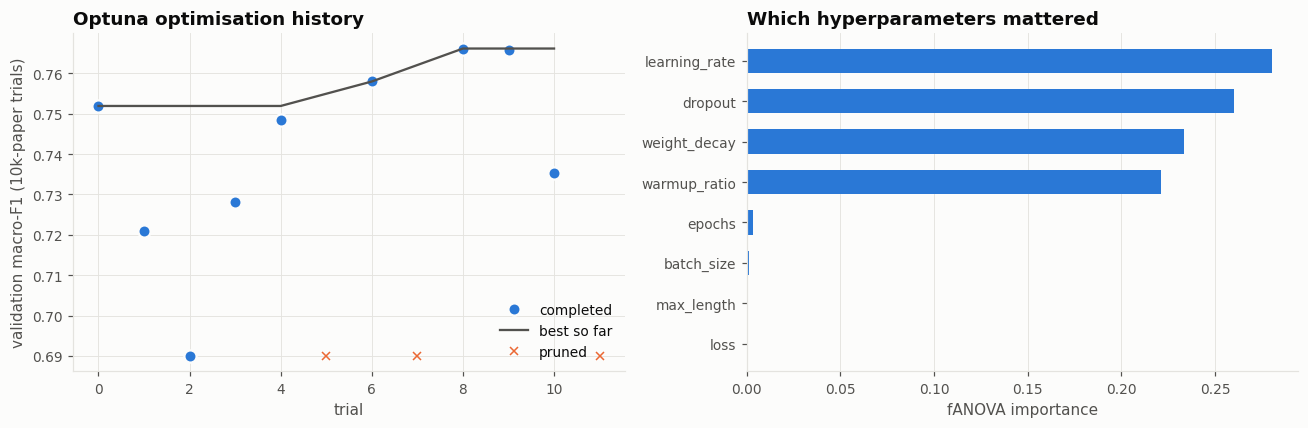

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
done = trials[trials["state"] == "COMPLETE"]
pruned = trials[trials["state"] == "PRUNED"]
ax = axes[0]
ax.plot(done["number"], done["value"], "o", color=viz.ACCENT, label="completed", mec=viz.SURFACE, mew=1.5, ms=8)
ax.plot(done["number"], done["value"].cummax(), "-", color=viz.TEXT_2, lw=1.5, label="best so far")
if len(pruned):
    ax.plot(pruned["number"], [done["value"].min()] * len(pruned), "x", color=viz.SERIES[1], label="pruned")
ax.set_xlabel("trial")
ax.set_ylabel("validation macro-F1 (10k-paper trials)")
ax.set_title("Optuna optimisation history")
ax.legend(loc="lower right")

try:
    imp = optuna.importance.get_param_importances(study)
except Exception as e:  # needs >= 2 completed trials with varied params
    imp = {}
    print("importance unavailable:", e)
ax = axes[1]
if imp:
    names, vals = list(imp)[::-1], list(imp.values())[::-1]
    ax.barh(names, vals, color=viz.ACCENT, height=0.6)
    ax.set_xlabel("fANOVA importance")
ax.set_title("Which hyperparameters mattered")
ax.grid(axis="y", visible=False)
fig.tight_layout()
viz.save(fig, "fig15_optuna", FIG_DIR)
save_json({"best_params": study.best_params, "best_value": study.best_value, "importance": imp},
          RESULTS_DIR / "optuna_best.json")

## 3. Baseline grid search

In [5]:
grid = baseline_grid(train["text"], y_tr, val["text"], y_va, sp.names)
grid.to_csv(RESULTS_DIR / "baseline_grid.csv", index=False)
grid

{'C': 1.0, 'ngram_max': 1, 'class_weight': 'balanced', 'macro_f1': 0.7665742426560785, 'accuracy': 0.7591891891891892, 'fit_seconds': 14.305329322814941}


{'C': 1.0, 'ngram_max': 1, 'class_weight': 'None', 'macro_f1': 0.766396281243752, 'accuracy': 0.7589189189189189, 'fit_seconds': 18.28828263282776}


{'C': 1.0, 'ngram_max': 2, 'class_weight': 'balanced', 'macro_f1': 0.7569286659726212, 'accuracy': 0.7486486486486487, 'fit_seconds': 41.668025970458984}


{'C': 1.0, 'ngram_max': 2, 'class_weight': 'None', 'macro_f1': 0.7565366375843653, 'accuracy': 0.7498648648648648, 'fit_seconds': 54.30557370185852}


{'C': 4.0, 'ngram_max': 1, 'class_weight': 'balanced', 'macro_f1': 0.7732334344272732, 'accuracy': 0.7656756756756756, 'fit_seconds': 20.073524475097656}


...

{'C': 16.0, 'ngram_max': 1, 'class_weight': 'balanced', 'macro_f1': 0.7652786421749207, 'accuracy': 0.7570270270270271, 'fit_seconds': 29.322648286819458}


{'C': 16.0, 'ngram_max': 1, 'class_weight': 'None', 'macro_f1': 0.7637098519952716, 'accuracy': 0.7558108108108108, 'fit_seconds': 27.471275329589844}


{'C': 16.0, 'ngram_max': 2, 'class_weight': 'balanced', 'macro_f1': 0.7761165644455065, 'accuracy': 0.7687837837837838, 'fit_seconds': 67.87775111198425}


{'C': 16.0, 'ngram_max': 2, 'class_weight': 'None', 'macro_f1': 0.774325927745831, 'accuracy': 0.7671621621621622, 'fit_seconds': 86.83126521110535}


,C,ngram_max,class_weight,macro_f1,accuracy,fit_seconds
10,16.0,2,balanced,0.776117,0.768784,67.877751
11,16.0,2,None,0.774326,0.767162,86.831265
4,4.0,1,balanced,0.773233,0.765676,20.073524
5,4.0,1,None,0.771671,0.764595,23.776539
6,4.0,2,balanced,0.771020,0.763243,75.361714
7,4.0,2,None,0.769448,0.762703,72.605627
0,1.0,1,balanced,0.766574,0.759189,14.305329
1,1.0,1,None,0.766396,0.758919,18.288283
8,16.0,1,balanced,0.765279,0.757027,29.322648
9,16.0,1,None,0.763710,0.755811,27.471275


## 4. Final models on the test set
Default vs tuned configuration, each retrained on the 20k training subset with up to three seeds (as many as the time budget allows).
The test split is used here for the first and only time.

In [6]:
bp = study.best_params
tuned_cfg = replace(TrainConfig(model_name=BEST_MODEL), early_stopping_patience=1,
                    **{k: bp[k] for k in ["learning_rate", "batch_size", "epochs", "warmup_ratio",
                                          "weight_decay", "max_length", "loss", "dropout"]})
configs = {"default": TrainConfig(model_name=BEST_MODEL), "tuned": tuned_cfg}

final_rows, per_class = [], {}
# Seed-major order: the first seed of both configs always runs; later seeds run only if they fit.
seed_hours = 2 * RUN_HOURS
for seed in SEEDS:
    if seed != SEEDS[0] and hours_left() < seed_hours * 1.1 + 0.25:
        print(f"skipping seed {seed}: {hours_left():.2f} h left, a seed takes ~{seed_hours:.2f} h")
        break
    seed_start = time.time()
    for label, cfg in configs.items():
        scores, info = train_transformer(replace(cfg, seed=seed), train["text"], y_tr,
                                         {"val": (val["text"], y_va), "test": (test["text"], y_te)},
                                         len(sp), f"/tmp/ckpt/final_{label}_{seed}")
        for split, y in [("val", y_va), ("test", y_te)]:
            m = evaluate.metrics(y, scores[split], sp.names)
            final_rows.append({"config": label, "seed": seed, "split": split,
                               **{k: v for k, v in m.items() if k != "per_class"}})
            if split == "test" and seed == SEEDS[0]:
                per_class[label] = m["per_class"]
        print(final_rows[-1], f"| {hours_left():.2f} h left", flush=True)
        pd.DataFrame(final_rows).to_csv(RESULTS_DIR / "final_results_runs.csv", index=False)
        torch.cuda.empty_cache()
    seed_hours = (time.time() - seed_start) / 3600

g = grid.iloc[0]
scores, _ = tfidf_logreg(train["text"], y_tr, {"val": val["text"], "test": test["text"]}, C=g["C"],
                         ngram_max=int(g["ngram_max"]), class_weight=None if g["class_weight"] == "None" else "balanced")
for split, y in [("val", y_va), ("test", y_te)]:
    m = evaluate.metrics(y, scores[split], sp.names)
    final_rows.append({"config": "baseline (tuned)", "seed": 0, "split": split,
                       **{k: v for k, v in m.items() if k != "per_class"}})

final = pd.DataFrame(final_rows)
final.to_csv(RESULTS_DIR / "final_results_runs.csv", index=False)
summary = (final.groupby(["config", "split"])[["accuracy", "macro_f1", "micro_f1", "top3_accuracy"]]
           .agg(mean_std).reset_index())
summary.to_csv(RESULTS_DIR / "final_results_summary.csv", index=False)
save_json({"model": BEST_MODEL, "default": asdict(configs["default"]), "tuned": asdict(tuned_cfg),
           "per_class_test": per_class}, RESULTS_DIR / "final_configs.json")
summary

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Map:   0%|          | 0/20000 [00:00<?, ? examples/s]

Map:   0%|          | 0/7400 [00:00<?, ? examples/s]

Map:   0%|          | 0/7400 [00:00<?, ? examples/s]

...

[transformers] There were unexpected keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.beta', 'bert.embeddings.LayerNorm.gamma', 'bert.encoder.layer.0.attention.output.LayerNorm.beta', 'bert.encoder.layer.0.attention.output.LayerNorm.gamma', 'bert.encoder.layer.0.output.LayerNorm.beta', 'bert.encoder.layer.0.output.LayerNorm.gamma', 'bert.encoder.layer.1.attention.output.LayerNorm.beta', 'bert.encoder.layer.1.attention.output.LayerNorm.gamma', 'bert.encoder.layer.1.output.LayerNorm.beta', 'bert.encoder.layer.1.output.LayerNorm.gamma', 'bert.encoder.layer.2.attention.output.LayerNorm.beta', 'bert.encoder.layer.2.attention.output.LayerNorm.gamma', 'bert.encoder.layer.2.output.LayerNorm.beta', 'bert.encoder.layer.2.output.LayerNorm.gamma', 'bert.encoder.layer.3.attention.output.LayerNorm.beta', 'bert.encoder.layer.3.attention.output.LayerNorm.gamma', 'bert.encoder.layer.3.output.LayerNorm.beta', 'bert.encoder.layer.3.output.LayerNorm.gamma', 'bert.encoder.layer.4.attention.

{'train_runtime': '1753', 'train_samples_per_second': '34.23', 'train_steps_per_second': '1.07', 'train_loss': '0.6284', 'epoch': '3'}


{'config': 'tuned', 'seed': 42, 'split': 'test', 'n_classes': 12, 'accuracy': 0.7732432432432432, 'macro_f1': 0.7816048146591502, 'micro_f1': 0.7732432432432432, 'weighted_f1': 0.7727490284250984, 'top3_accuracy': 0.9554054054054054} | 0.87 h left


skipping seed 43: 0.87 h left, a seed takes ~1.05 h


,config,split,accuracy,macro_f1,micro_f1,top3_accuracy
0,baseline (tuned),test,0.7703 ± 0.0000,0.7778 ± 0.0000,0.7703 ± 0.0000,0.9554 ± 0.0000
1,baseline (tuned),val,0.7688 ± 0.0000,0.7761 ± 0.0000,0.7688 ± 0.0000,0.9536 ± 0.0000
2,default,test,0.7705 ± 0.0000,0.7789 ± 0.0000,0.7705 ± 0.0000,0.9574 ± 0.0000
3,default,val,0.7708 ± 0.0000,0.7783 ± 0.0000,0.7708 ± 0.0000,0.9562 ± 0.0000
4,tuned,test,0.7732 ± 0.0000,0.7816 ± 0.0000,0.7732 ± 0.0000,0.9554 ± 0.0000
5,tuned,val,0.7723 ± 0.0000,0.7794 ± 0.0000,0.7723 ± 0.0000,0.9565 ± 0.0000


PosixPath('/kaggle/working/reports/figures/fig16_final_test.png')

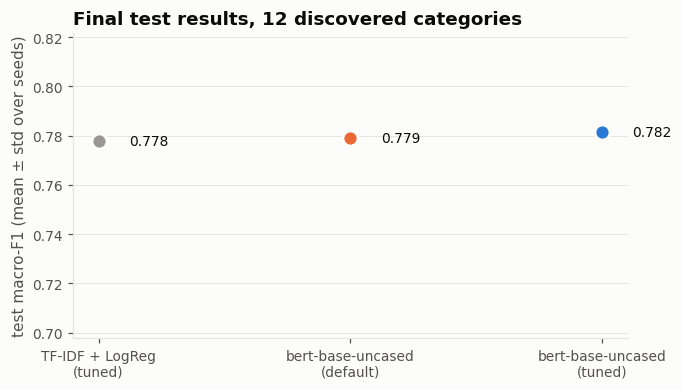

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
t = final[final["split"] == "test"]
order = ["baseline (tuned)", "default", "tuned"]
# Dot plot rather than bars: the axis is zoomed in, and bars must start at zero.
for i, c in enumerate(order):
    v = t.loc[t["config"] == c, "macro_f1"]
    color = [viz.NEUTRAL, viz.SERIES[1], viz.ACCENT][i]
    ax.plot([i] * len(v), v, "o", color=color, alpha=0.35, ms=6)
    ax.errorbar(i, v.mean(), yerr=v.std() if len(v) > 1 else None, fmt="o", color=color, ms=10,
                mec=viz.SURFACE, mew=2, capsize=5, ecolor=viz.TEXT_2, elinewidth=1)
    ax.text(i + 0.12, v.mean(), f"{v.mean():.3f}", va="center", fontsize=9)
ax.set_xticks(range(3), ["TF-IDF + LogReg\n(tuned)", f"{BEST_MODEL}\n(default)", f"{BEST_MODEL}\n(tuned)"])
lo = t["macro_f1"].min()
ax.set_ylim(max(0, lo - 0.08), min(1, t["macro_f1"].max() + 0.04))
ax.set_ylabel("test macro-F1 (mean ± std over seeds)")
ax.set_title(f"Final test results, {len(sp)} discovered categories")
ax.grid(axis="x", visible=False)
viz.save(fig, "fig16_final_test", FIG_DIR)